## Importing Libararies

In [1]:
import string
import pandas as pd
import numpy as np

from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

**Insight:** Standard NLP-classification stack — NLTK for stop-words and stemming, TF-IDF for vectorisation, scikit-learn for splitting. Models and metrics are imported later (cell 28).

## Importing Dataset

In [2]:
formspring_dataset = pd.read_csv("Formspring.csv")

print("First 10 Elements from the 'Dataset - Formspring.csv':")
print('-' * 63)
formspring_dataset.head(10)

First 10 Elements from the 'Dataset - Formspring.csv':
---------------------------------------------------------------


,text,answer
0,Q: what&#039;s your favorite song? :D<br>A: I ...,No
1,Q: <3<br>A: </3 ? haha jk! <33,No
2,Q: &quot;hey angel you duh sexy&quot;<br>A: R...,No
3,Q: (:<br>A: ;(,No
4,Q: ******************MEOWWW*******************...,No
5,Q: any makeup tips? i suck at doing my makeup ...,No
6,Q: Apriiiiiiiiiiiill!!! I miss uuuu! It&#039;s...,No
7,Q: Are you a morning or night person?<br>A: Ni...,No
8,Q: are you a trusting person?<br>A: alreadi an...,No
9,Q: are you a trusting person?<br>A: Yes veryy ...,No


**Insight:**
- The Formspring data has one `text` column in which the question and the reply are fused as `Q: … <br>A: …`; `answer` is the Yes/No target (cyberbullying flagged or not).
- The raw text is noisy: HTML entities (`&#039;`, `&quot;`), `<br>` tags, emoticons (`:D`, `<3`) and slang or stretched spellings (`uuuu`, `yuh`, `wht`). Cleaning will matter.
- The first rows are harmless chit-chat, which hints that bullying posts are a small minority (confirmed in cell 10).

In [3]:
print("Last 10 Elements from the 'Dataset - Formspring.csv':")
print('-' * 63)
formspring_dataset.tail(10)

Last 10 Elements from the 'Dataset - Formspring.csv':
---------------------------------------------------------------


,text,answer
13137,Q: Your bio says &quot;Always ready for advent...,No
13138,Q: your going to mcdonalds what do you order ...,No
13139,Q: Your home alone. 2 robbers (of the opposite...,No
13140,Q: Your parents are divorced. One of them gets...,No
13141,Q: your thoughts on 2012? I think it&#039;ll b...,No
13142,Q: Youre at a party and your friend who drove ...,No
13143,Q: Youu2019re awesome :] Give yourself a compl...,No
13144,Q: Yu play with yurself ?<br>A: all the time. ...,No
13145,Q: yukk beer is disgusting. i can only drink i...,No
13146,Q: if i told u den it would make it all the le...,No


**Insight:** Same `Q: … <br>A: …` format at the end of the file, and again all `No`. Some rows carry broken Unicode escapes (e.g. `Youu2019re` for *You're*), another source of noise. The rows appear to be ordered by question text, not randomly, so shuffling before splitting is important (`train_test_split` does this by default).

In [4]:
print(f"The 'Dataset - Formspring.csv' has {formspring_dataset.shape[0]:,} Rows and "\
      f"{formspring_dataset.shape[1]} columns.")

The 'Dataset - Formspring.csv' has 13,147 Rows and 2 columns.


**Insight:** 13,147 rows × 2 columns — a modest text-only dataset, well suited to classical ML (TF-IDF + linear/SVM/NB models). There is no metadata such as user or timestamp, so the model can only learn from the wording.

In [5]:
formspring_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 13147 entries, 0 to 13146
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    13147 non-null  str  
 1   answer  13147 non-null  str  
dtypes: str(2)
memory usage: 1.9 MB


**Insight:** No nulls in either column and both are string-typed, so the target (`Yes`/`No`) must be encoded before modelling. The dataset is small in memory (~1.9 MB).

In [6]:
formspring_dataset.drop_duplicates(inplace=True)

C:\Users\ramvi\AppData\Local\Temp\ipykernel_7460\2865427139.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  formspring_dataset.drop_duplicates(inplace=True)


**Insight:** Only 3 exact duplicates were removed (13,147 → 13,144, ≈0.02%), so duplication is not a real problem here. Removing them also prevents identical posts from landing in both train and test. *Note:* `inplace=True` triggers a deprecation warning; `df = df.drop_duplicates()` is the future-proof form.

In [7]:
print("A generate descriptive statistics from the 'Dataset - Formspring.csv':")
print('-' * 73)
formspring_dataset.describe()

A generate descriptive statistics from the 'Dataset - Formspring.csv':
-------------------------------------------------------------------------


,text,answer
count,13144,13144
unique,13144,2
top,Q: what&#039;s your favorite song? :D<br>A: I ...,No
freq,1,12292


**Insight:** All 13,144 posts are now unique. The label has two values and the top value, `No`, appears 12,292 times — the first sign of heavy class imbalance.

In [8]:
print("Detecting missing values from the 'Dataset - Formspring.csv':")
print('-' * 63)
print(formspring_dataset.isnull().sum())

Detecting missing values from the 'Dataset - Formspring.csv':
---------------------------------------------------------------
text      0
answer    0
dtype: int64


**Insight:** No missing values, so no imputation is needed. *Note:* `isnull()` can't detect empty replies — some rows look like `Q: ask something<br>A:` (visible in the cell 41 output) — but these are legitimate non-bullying posts, so they can stay.

In [9]:
print("A value count for the 'Element - answer', from the 'Dataset - Formspring.csv':")
print('-' * 83)
formspring_dataset["answer"].value_counts()

A value count for the 'Element - answer', from the 'Dataset - Formspring.csv':
-----------------------------------------------------------------------------------


answer
No     12292
Yes      852
Name: count, dtype: int64

**Insight:**
- `No` = 12,292 (≈93.5%) vs `Yes` = 852 (≈6.5%), roughly a **14 : 1** imbalance.
- A model that always predicts "No" would already score ≈93.5% accuracy, so **accuracy is a misleading metric** here. Precision, recall and F1 *for the bullying class* are what matter.
- This calls for a stratified split, class weights or resampling, and threshold tuning.

In [10]:
# Creates a new "Instance - Lenght" and stores the sum of the length values from the "Column - text":
formspring_dataset["Length"] = formspring_dataset.text.apply(len)

# Encodes the "Column - answer" from the "Dataset - Formspring.csv" to boolean format:
formspring_dataset.answer = formspring_dataset.answer.map({
    "Yes": 1, 
    "No": 0
})

**Insight:** Adds `Length` (characters per post) and encodes `Yes → 1`, `No → 0`. `Length` is never used as a model feature afterwards (only TF-IDF is), so it is an unused idea: it could be tested for whether bullying posts are systematically longer or shorter.

## Data Pre-Processing

In [11]:
formspring_text_features = formspring_dataset["text"].copy()
tfid_vectorizer = TfidfVectorizer(encoding="english")
formspring_features = tfid_vectorizer.fit_transform(formspring_text_features)

print("Text Features from the 'Dataset - Formspring.csv':")
print('-' * 63)
print(formspring_text_features)

Text Features from the 'Dataset - Formspring.csv':
---------------------------------------------------------------
0        Q: what&#039;s your favorite song? :D<br>A: I ...
1                           Q: <3<br>A: </3 ? haha jk! <33
2        Q: &quot;hey angel  you duh sexy&quot;<br>A: R...
3                                           Q: (:<br>A: ;(
4        Q: ******************MEOWWW*******************...
                               ...                        
13142    Q: Youre at a party and your friend who drove ...
13143    Q: Youu2019re awesome :] Give yourself a compl...
13144    Q: Yu play with yurself ?<br>A: all the time. ...
13145    Q: yukk beer is disgusting. i can only drink i...
13146    Q: if i told u den it would make it all the le...
Name: text, Length: 13144, dtype: str


**Insight:**
- TF-IDF is fitted on the **raw** text. *Note:* `encoding="english"` only controls how bytes are decoded and has no effect on text that is already a string; stop-word removal would need `stop_words="english"`. So stop-words and HTML fragments (`br`, `quot`, `039`) remain in this matrix.
- The vectorizer is fitted on the whole dataset before the train/test split, so IDF weights are computed with test rows included (a mild leak). Fitting inside a `Pipeline` on the training data only avoids this.
- The printed output is just the raw `text` column.

In [12]:
print("Features from the 'Dataset - Formspring.csv':")
print('-' * 53)
print(formspring_features)

Features from the 'Dataset - Formspring.csv':
-----------------------------------------------------
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 254346 stored elements and shape (13144, 18775)>
  Coords	Values
  (0, 17947)	0.15983810051725175
  (0, 4)	0.21165743444583593
  (0, 18614)	0.16451661035141804
  (0, 6020)	0.5901452730051981
  (0, 15130)	0.33737799558257453
  (0, 2417)	0.06294561991585858
  (0, 9775)	0.19037637377052513
  (0, 16688)	0.2637659067952349
  (0, 10321)	0.3006714911498645
  (0, 15135)	0.43794013542386573
  (0, 16619)	0.13669658751734107
  (0, 7574)	0.1727229244867797
  (1, 2417)	0.10517890049395773
  (1, 7324)	0.3741444572759832
  (1, 8965)	0.6831172577114805
  (1, 212)	0.6183074770672669
  (2, 2417)	0.05634840358181634
  (2, 7324)	0.20044365150687118
  (2, 13327)	0.5094140679380995
  (2, 7765)	0.2886449549420205
  (2, 1044)	0.43815090396391915
  (2, 18600)	0.08653596954097055
  (2, 5157)	0.4248307736953435
  (2, 14472)	0.33718811827031564
  (2, 135

**Insight:** The matrix is 13,144 × 18,775 with 254,346 non-zero entries — about 19 terms per post and a density of ≈0.1%. That extreme sparsity is typical for short texts and suits linear models and SVMs. Feature index 2417 appears in nearly every row with a small weight; it is most likely the `br` token from the `<br>` tag, i.e. an uninformative artefact.

In [13]:
saved_formspring_df = pd.DataFrame(formspring_text_features)

saved_formspring_df.to_csv("Formspring Text Features.csv")

**Insight:** Despite the file name (`Formspring Text Features.csv`), this saves the *raw text* column, not the TF-IDF features. It isn't needed for modelling, but the name is misleading.

## Label Encoding

In [14]:
from sklearn.preprocessing import LabelEncoder

column = ["answer"]

print("column:", column)

column: ['answer']


**Insight:** Only `answer` needs encoding; `text` is handled by TF-IDF.

In [15]:
label_encoder = LabelEncoder()

for i in column:
    # print(i)
    formspring_dataset[i] = label_encoder.fit_transform(formspring_dataset[i])

print("Formspring Dataset Data Types:")
print('-' * 33)
print(formspring_dataset.dtypes)

Formspring Dataset Data Types:
---------------------------------
text        str
answer    int64
Length    int64
dtype: object


**Insight:** `answer` was already mapped to 0/1 in cell 11, so `LabelEncoder` is an identity transform here (redundant but harmless). Final dtypes — `text` (string), `answer` (int64), `Length` (int64) — confirm the data is ready for modelling.

In [16]:
print("Frist 10 Elements from the 'Datset - Formspring.csv':")
print('-' * 63)
formspring_dataset.head(10)

Frist 10 Elements from the 'Datset - Formspring.csv':
---------------------------------------------------------------


,text,answer,Length
0,Q: what&#039;s your favorite song? :D<br>A: I ...,0,84
1,Q: <3<br>A: </3 ? haha jk! <33,0,30
2,Q: &quot;hey angel you duh sexy&quot;<br>A: R...,0,69
3,Q: (:<br>A: ;(,0,14
4,Q: ******************MEOWWW*******************...,0,66
5,Q: any makeup tips? i suck at doing my makeup ...,0,114
6,Q: Apriiiiiiiiiiiill!!! I miss uuuu! It&#039;s...,0,120
7,Q: Are you a morning or night person?<br>A: Ni...,0,59
8,Q: are you a trusting person?<br>A: alreadi an...,0,50
9,Q: are you a trusting person?<br>A: Yes veryy ...,0,80


**Insight:** The head confirms the 0/1 encoding and the new `Length` column. Posts are short (≈14–120 characters in this sample), consistent with chat-style Q&A.

In [17]:
print("Last 10 Elements from the 'Dataset - Formspring.csv':")
print('-' * 63)
formspring_dataset.tail(10)

Last 10 Elements from the 'Dataset - Formspring.csv':
---------------------------------------------------------------


,text,answer,Length
13137,Q: Your bio says &quot;Always ready for advent...,0,276
13138,Q: your going to mcdonalds what do you order ...,0,80
13139,Q: Your home alone. 2 robbers (of the opposite...,0,201
13140,Q: Your parents are divorced. One of them gets...,0,315
13141,Q: your thoughts on 2012? I think it&#039;ll b...,0,122
13142,Q: Youre at a party and your friend who drove ...,0,316
13143,Q: Youu2019re awesome :] Give yourself a compl...,0,105
13144,Q: Yu play with yurself ?<br>A: all the time. ...,0,76
13145,Q: yukk beer is disgusting. i can only drink i...,0,160
13146,Q: if i told u den it would make it all the le...,0,125


**Insight:** The last 10 rows are all class 0, and lengths range up to ≈316 characters here. Again, bullying posts are rare.

In [18]:
formspring_features_train, formspring_features_test, formspring_labels_train, \
formspring_labels_test = train_test_split(
    formspring_features,
    formspring_dataset["answer"],
    test_size=0.3,
    random_state=4861
)

**Insight:**
- A 70/30 split gives 9,200 training and 3,944 test posts.
- The split is **not stratified**: the test set ends up with 245 bullying posts (≈6.2%) versus ≈6.6% in train (607 posts). With only 245 positives, each missed post moves recall by ≈0.4 points, so minority-class metrics will be noisy. `stratify=y` plus cross-validation would give more stable estimates.

In [19]:
print("Features Train from the 'Dataset - Formspring.csv':")
print('-' * 53)

print(formspring_features_train)

Features Train from the 'Dataset - Formspring.csv':
-----------------------------------------------------
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 178415 stored elements and shape (9200, 18775)>
  Coords	Values
  (0, 18614)	0.07074590243107504
  (0, 2417)	0.027068055167916855
  (0, 1030)	0.06417752668814737
  (0, 1978)	0.132037828859859
  (0, 17469)	0.13790429756424719
  (0, 7044)	0.12536824887442607
  (0, 6534)	0.1417492513981536
  (0, 7286)	0.15120099054209124
  (0, 8726)	0.18996525783636825
  (0, 18045)	0.18325681487919415
  (0, 1342)	0.20136668714652306
  (0, 5294)	0.23527654429007896
  (0, 2008)	0.2462516962050161
  (0, 8907)	0.24021163424767822
  (0, 8115)	0.25403869041296157
  (0, 10940)	0.25403869041296157
  (0, 6105)	0.2650138423278987
  (0, 10682)	0.2462516962050161
  (0, 16722)	0.2650138423278987
  (0, 7085)	0.2650138423278987
  (0, 7672)	0.2650138423278987
  (0, 4337)	0.2650138423278987
  (0, 3856)	0.2650138423278987
  (1, 2417)	0.04757845335039932
  (1

**Insight:** Training matrix: 9,200 × 18,775 with 178,415 non-zero values — the same sparse structure as the full data.

In [20]:
print("Features Test from the 'Dataset - Formspring.csv':")
print('-' * 53)
print(formspring_features_test)

Features Test from the 'Dataset - Formspring.csv':
-----------------------------------------------------
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 75931 stored elements and shape (3944, 18775)>
  Coords	Values
  (0, 2417)	0.04151705937824222
  (0, 18484)	0.19538527707618492
  (0, 11877)	0.3777015463399222
  (0, 18695)	0.6978482273735077
  (0, 7047)	0.40647897899309066
  (0, 10298)	0.40647897899309066
  (1, 2417)	0.0490815281958584
  (1, 9775)	0.14844501284654407
  (1, 18600)	0.07537600639943774
  (1, 4873)	0.11923248659057858
  (1, 11937)	0.14979215249138808
  (1, 1030)	0.23274158901658373
  (1, 6837)	0.17907946016587672
  (1, 11484)	0.3292878929806421
  (1, 16434)	0.18989992410049497
  (1, 6562)	0.21063015102862537
  (1, 16359)	0.20124850426625374
  (1, 17909)	0.21299474471283622
  (1, 18045)	0.3322929730554626
  (1, 5380)	0.4805400422682295
  (1, 6899)	0.4805400422682295
  (2, 2417)	0.04431031156748817
  (2, 11563)	0.13972776098118733
  (2, 8434)	0.367214811262974

**Insight:** Test matrix: 3,944 × 18,775 (75,931 non-zeros). The column count matches train because the vocabulary was built on the full corpus (see the leakage note in cell 13).

In [21]:
print("First 10 Elements from Formspring Labels Train:")
print('-' * 53)
formspring_labels_train.head(10)

First 10 Elements from Formspring Labels Train:
-----------------------------------------------------


4299     0
8283     0
4780     1
7003     0
7246     0
5326     0
12012    0
3717     0
6491     0
5673     0
Name: answer, dtype: int64

**Insight:** Training labels are overwhelmingly `0`, with the occasional `1` (e.g. index 4780). This is the imbalance a model must learn from.

In [22]:
print("First 10 Elements from Formspring Labels Train:")
print('-' * 53)
formspring_labels_train.tail(10)

First 10 Elements from Formspring Labels Train:
-----------------------------------------------------


3054     0
4395     0
10832    0
9088     0
2704     1
4128     0
9566     0
9816     0
12748    0
2101     0
Name: answer, dtype: int64

**Insight:** More training labels, again mostly `0`. *Note:* the printed header says "First 10" but the cell shows the last 10 (`.tail`).

In [23]:
print("First 10 Elements from Formspring Label Test:")
print('-' * 53)
formspring_labels_test.head(10)

First 10 Elements from Formspring Label Test:
-----------------------------------------------------


3002     0
10360    0
6940     0
9311     0
9938     0
2689     0
4497     0
1880     0
4137     0
12742    0
Name: answer, dtype: int64

**Insight:** The first test labels are all `0`, as expected given ≈94% of the test set is negative.

In [24]:
print("Last 10 Elements from Formspring Labels Test:")
print('-' * 53)
formspring_labels_test.tail(10)

Last 10 Elements from Formspring Labels Test:
-----------------------------------------------------


12729    0
2928     0
6721     0
7064     0
9019     0
3350     0
4592     0
4849     0
1001     0
10966    0
Name: answer, dtype: int64

**Insight:** The last test labels are also all `0`; the class skew is the same in the test set (3,699 negatives vs 245 positives, as the confusion matrices later confirm).

In [25]:
from sklearn.model_selection import GridSearchCV

from sklearn.svm import (SVR, SVC)
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import (Ridge, RidgeClassifier, SGDRegressor, SGDClassifier, LogisticRegression)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from matplotlib import style
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings("ignore")


**Insight:** This sets up the models, grid search and metrics. *Note:* `warnings.filterwarnings("ignore")` hides convergence warnings, which matter for the capped `max_iter` runs of SVR/SVC/saga later on.

In [26]:
# ----------------------------- Metric Scores: C-Support Vector Classification ----------------------------- #
svc = SVC(kernel="sigmoid", gamma=1.0)

svc.fit(formspring_features_train, formspring_labels_train)

svc_prediction = svc.predict(formspring_features_test)
svc_accuracy_score = accuracy_score(formspring_labels_test, svc_prediction)
svc_precision_score = precision_score(formspring_labels_test, svc_prediction)
svc_recall_score = recall_score(formspring_labels_test, svc_prediction)
svc_f1_score = f1_score(formspring_labels_test, svc_prediction)
# ---------------------------------------------------------------------------------------------------------- #
# -------------------------------------- Metric Scores: MultinomialNB -------------------------------------- #
mnb = MultinomialNB(alpha=0.2)

mnb.fit(formspring_features_train, formspring_labels_train)

mnb_prediction = mnb.predict(formspring_features_test)
mnb_accuracy_score = accuracy_score(formspring_labels_test, mnb_prediction)
mnb_precision_score = precision_score(formspring_labels_test, mnb_prediction)
mnb_recall_score = recall_score(formspring_labels_test, mnb_prediction)
mnb_f1_score = f1_score(formspring_labels_test, mnb_prediction)
# ---------------------------------------------------------------------------------------------------------- #
# -------------------------------------- Metric Scores: DecisionTreeClassifier -------------------------------------- #
dtc = DecisionTreeClassifier()

dtc.fit(formspring_features_train, formspring_labels_train)

dtc_prediction = dtc.predict(formspring_features_test)
dtc_accuracy_score = accuracy_score(formspring_labels_test, dtc_prediction)
dtc_prediction_score = precision_score(formspring_labels_test, dtc_prediction)
dtc_recall_score = recall_score(formspring_labels_test, dtc_prediction)
dtc_f1_score = f1_score(formspring_labels_test, dtc_prediction)
# ---------------------------------------------------------------------------------------------------------- #
print(f"""_______Evaluation for: C-Support Vector Classification______
Model Typee:      {svc}
Accuracy Score:   {svc_accuracy_score:%}
Precision Score:  {svc_precision_score:%}
Recall Score:     {svc_recall_score:%}
F1-Score:         {svc_f1_score:%}

C-Support Vector Classification - Confusion Matrix:
{confusion_matrix(formspring_labels_test, svc_prediction)}

C-Support Vector Classification - Classification Report:
{classification_report(formspring_labels_test, svc_prediction)}
----------------------------THE END----------------------------
______Evaluation for: Multinomial Navie Bayes Classifier_______
Model Type:       {mnb}
Accuracy Score:   {mnb_accuracy_score:%}
Precision Score:  {mnb_precision_score:%}
Recall Score:     {mnb_recall_score:%}
F1_score:         {mnb_f1_score:%}

C-Support Vector Classification - Confusion Matrix:
{confusion_matrix(formspring_labels_test, mnb_prediction)}

C-Support Vector Classification - Classification Report:
{classification_report(formspring_labels_test, mnb_prediction)}
----------------------------THE END----------------------------
__________Evaluation for: Decision Tree Classifier_____________
Model Type:        {dtc}
Accuracy Score:    {dtc_accuracy_score:%}
Precision Score:   {dtc_prediction_score:%}
Recall Score:      {dtc_recall_score:%}
F1-Score:          {dtc_f1_score}

C-Support Vector Classification - Confusion Matrix:
{confusion_matrix(formspring_labels_test, dtc_prediction)}

C-Support vector Classification - Classification Report:
{classification_report(formspring_labels_test, dtc_prediction)}
----------------------------THE END----------------------------""")
# ---------------------------------------------------------------------------------------------------------- #

_______Evaluation for: C-Support Vector Classification______
Model Typee:      SVC(gamma=1.0, kernel='sigmoid')
Accuracy Score:   95.055781%
Precision Score:  82.894737%
Recall Score:     25.714286%
F1-Score:         39.252336%

C-Support Vector Classification - Confusion Matrix:
[[3686   13]
 [ 182   63]]

C-Support Vector Classification - Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      3699
           1       0.83      0.26      0.39       245

    accuracy                           0.95      3944
   macro avg       0.89      0.63      0.68      3944
weighted avg       0.95      0.95      0.94      3944

----------------------------THE END----------------------------
______Evaluation for: Multinomial Navie Bayes Classifier_______
Model Type:       MultinomialNB(alpha=0.2)
Accuracy Score:   94.041582%
Precision Score:  56.944444%
Recall Score:     16.734694%
F1_score:         25.867508%

C-Support Vector Cl

**Insight — baseline models on raw TF-IDF (positive class = bullying):**

| Model | Accuracy | Precision | Recall | F1 | Confusion matrix [[TN, FP], [FN, TP]] |
|---|---|---|---|---|---|
| SVC (sigmoid, γ=1) | 95.06% | 82.9% | 25.7% | 39.3% | [[3686, 13], [182, 63]] |
| Multinomial NB (α=0.2) | 94.04% | 56.9% | 16.7% | 25.9% | [[3668, 31], [204, 41]] |
| Decision Tree | 93.26% | 44.7% | 36.3% | 40.1% | [[3589, 110], [156, 89]] |

- **SVC** is the most precise (when it flags bullying it is right ≈83% of the time) but it misses ≈74% of bullying posts.
- **Decision Tree** catches the most bullying posts (36% recall) but with many false alarms (110 FP, precision 45%), so it ends with the best F1 by a hair.
- **NB** is weakest on both precision and recall.
- Accuracy is 93–95% for all three against a 93.8% "always No" baseline (3,699 / 3,944), so the real differences show up only in the bullying-class recall and F1.

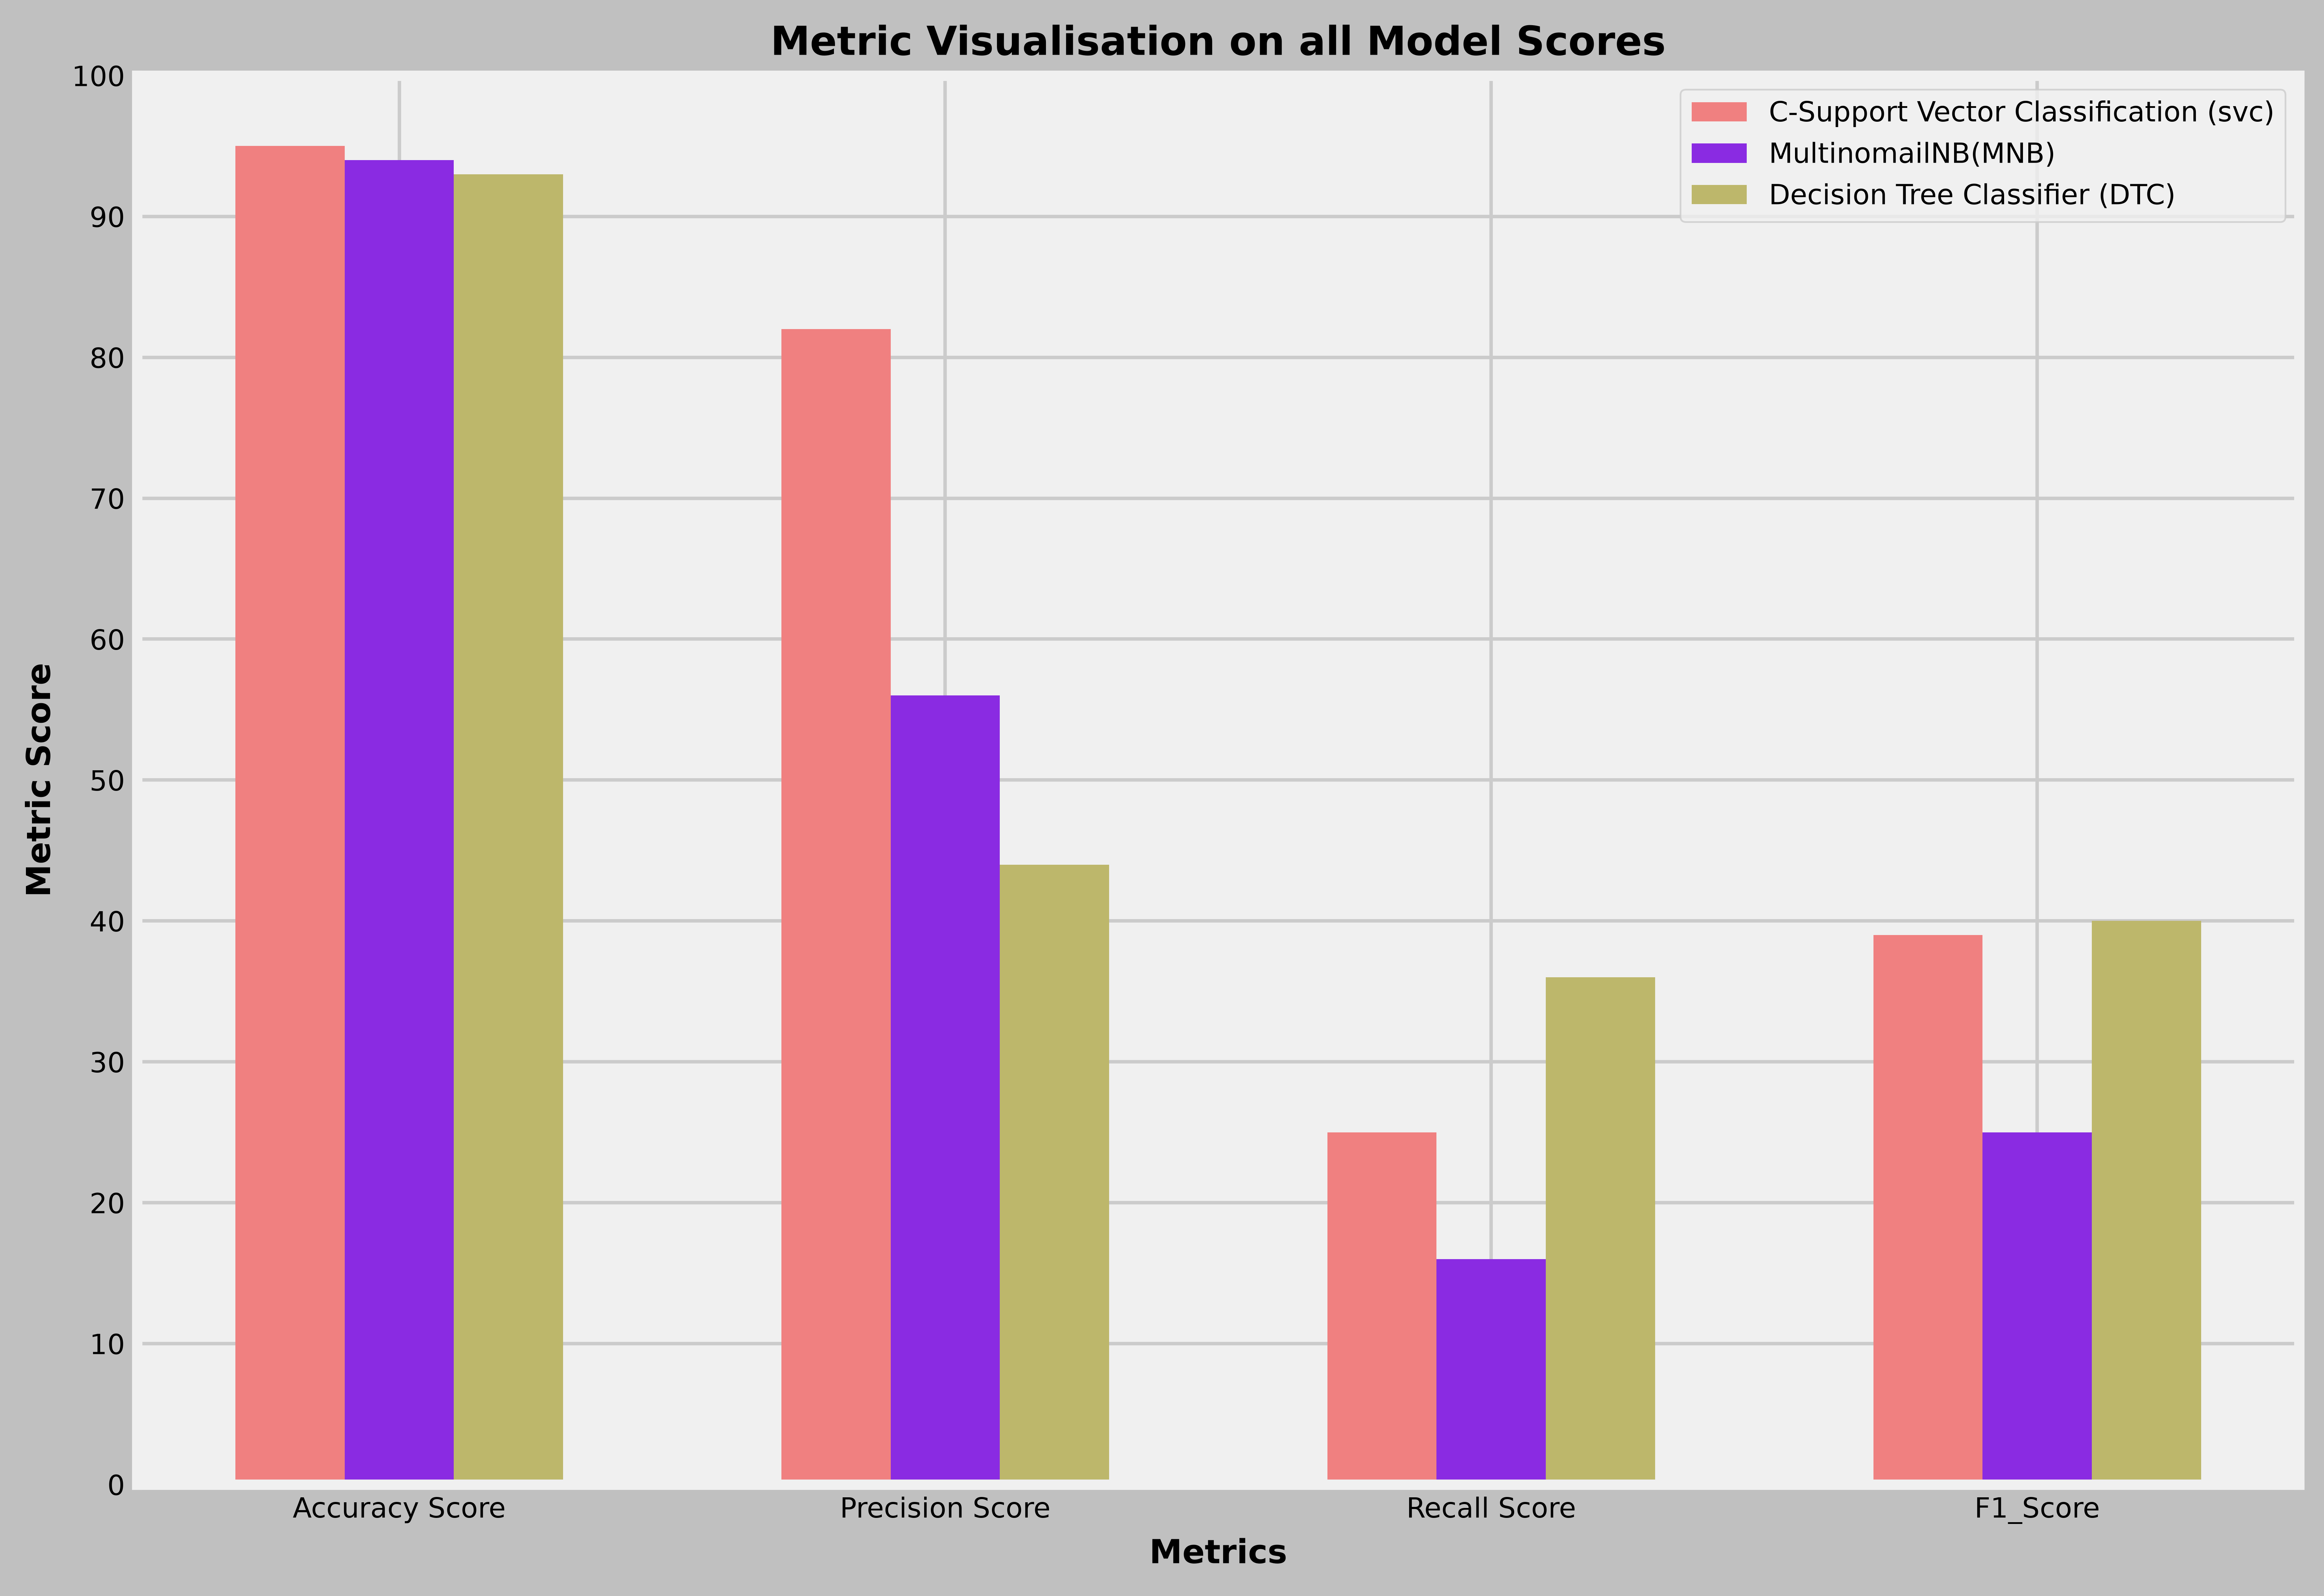

In [27]:
svc_scores = (
    int(svc_accuracy_score * 100),
    int(svc_precision_score * 100),
    int(svc_recall_score * 100),
    int(svc_f1_score * 100)
)
mnb_scores = (
    int(mnb_accuracy_score * 100),
    int(mnb_precision_score * 100),
    int(mnb_recall_score * 100),
    int(mnb_f1_score * 100)
)
dtc_scores = (
    int(dtc_accuracy_score * 100),
    int(dtc_prediction_score * 100),
    int(dtc_recall_score * 100),
    int(dtc_f1_score * 100)
)
x_grid = ["Accuracy Score", "Precision Score", "Recall Score", "F1_Score"]
y_grid = [value for value in range(0, 105, 10)]
xpos = np.arange(len(x_grid))
bar_width = .2

style.use("fivethirtyeight")
plt.rcParams['font.size'] = 8
plt.figure(figsize=(10, 7), dpi=700, facecolor="silver")
plt.title("Metric Visualisation on all Model Scores", fontweight = "bold")

plt.bar(xpos, svc_scores, width=bar_width, color="lightcoral", label="C-Support Vector Classification (svc)")
plt.bar((xpos + 0.2), mnb_scores, width=bar_width, color="blueviolet", label = "MultinomailNB(MNB)")
plt.bar((xpos + 0.4), dtc_scores, width=bar_width, color = "darkkhaki", label="Decision Tree Classifier (DTC)")
plt.xlabel("Metrics", fontweight = "bold")

plt.xticks((xpos + 0.2), x_grid)
plt.ylabel("Metric Score", fontweight = "bold")
plt.yticks(y_grid)
plt.legend()
plt.savefig("Workshop 2 - Graph.jpg", dpi=700)
plt.show()

**Insight:** The chart compares the three baselines. Scores are cut with `int()`, so they are truncated rather than rounded (e.g. SVC accuracy 95.06 → 95). Accuracy bars look nearly equal (93–95), while precision (82 / 56 / 44) and recall (25 / 16 / 36) differ sharply. That gap shows why accuracy alone hides the trade-offs between these models.

In [28]:
formspring_df = pd.read_csv("Formspring.csv")

print("First 10 Elements from the 'Dataset - Formspring.csv':")
print('-' * 63)
formspring_df[:10]

First 10 Elements from the 'Dataset - Formspring.csv':
---------------------------------------------------------------


,text,answer
0,Q: what&#039;s your favorite song? :D<br>A: I ...,No
1,Q: <3<br>A: </3 ? haha jk! <33,No
2,Q: &quot;hey angel you duh sexy&quot;<br>A: R...,No
3,Q: (:<br>A: ;(,No
4,Q: ******************MEOWWW*******************...,No
5,Q: any makeup tips? i suck at doing my makeup ...,No
6,Q: Apriiiiiiiiiiiill!!! I miss uuuu! It&#039;s...,No
7,Q: Are you a morning or night person?<br>A: Ni...,No
8,Q: are you a trusting person?<br>A: alreadi an...,No
9,Q: are you a trusting person?<br>A: Yes veryy ...,No


**Insight:** The data is reloaded to start a second, cleaner pipeline (with text pre-processing) from scratch. The same 10 rows appear, so the starting point is identical to cell 3.

In [29]:
print("Last 10 Elements from the 'Dataset - Formspring.csv':")
print('-' * 63)
formspring_df[-10:]

Last 10 Elements from the 'Dataset - Formspring.csv':
---------------------------------------------------------------


,text,answer
13137,Q: Your bio says &quot;Always ready for advent...,No
13138,Q: your going to mcdonalds what do you order ...,No
13139,Q: Your home alone. 2 robbers (of the opposite...,No
13140,Q: Your parents are divorced. One of them gets...,No
13141,Q: your thoughts on 2012? I think it&#039;ll b...,No
13142,Q: Youre at a party and your friend who drove ...,No
13143,Q: Youu2019re awesome :] Give yourself a compl...,No
13144,Q: Yu play with yurself ?<br>A: all the time. ...,No
13145,Q: yukk beer is disgusting. i can only drink i...,No
13146,Q: if i told u den it would make it all the le...,No


**Insight:** The tail is identical to the first pipeline, confirming the same source data.

In [30]:
formspring_df.drop_duplicates(inplace=True)

formspring_df_rows = formspring_df.shape[0]
formspring_df_columns = formspring_df.shape[1]

print("The Dataset - Formspring.csv has {rows:,} rows"\
      "and {columns} columns.".format(rows=formspring_df_rows, columns=formspring_df_columns))

The Dataset - Formspring.csv has 13,144 rowsand 2 columns.


**Insight:** Same shape after de-duplication: 13,144 rows × 2 columns, consistent with cell 7.

In [31]:
formspring_df.info()

<class 'pandas.DataFrame'>
Index: 13144 entries, 0 to 13146
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    13144 non-null  str  
 1   answer  13144 non-null  str  
dtypes: str(2)
memory usage: 2.0 MB


**Insight:** No nulls and string dtypes, the same as before. The data is ready for the new cleaning step.

In [32]:
print("A generate descriptive statistics from the 'Dataset - Formspring.csv':")
print('-' * 73)
formspring_df.describe()

A generate descriptive statistics from the 'Dataset - Formspring.csv':
-------------------------------------------------------------------------


,text,answer
count,13144,13144
unique,13144,2
top,Q: what&#039;s your favorite song? :D<br>A: I ...,No
freq,1,12292


**Insight:** 13,144 unique posts, with `No` as the most frequent label (12,292) — the same imbalance as earlier.

In [33]:
print("Detecting missing values from the 'Dataset - Formspring.csv")
print('-' * 63)
print(formspring_df.isnull().sum())

Detecting missing values from the 'Dataset - Formspring.csv
---------------------------------------------------------------
text      0
answer    0
dtype: int64


**Insight:** No missing values, confirmed again.

In [34]:
# Create a new "Instance - Lenght" and stores the sum of the length values from the "Column - text":
formspring_df["Length"] = formspring_df.text.apply(len)

# Encodes the "column - answer" from the "Dataset - Formspring.csv" to boolean format:
formspring_df.answer = formspring_df.answer.map({
    "Yes" : 1,
    "No" : 0
})

**Insight:** `Length` is added and labels are mapped to 0/1 once more. These steps repeat cells 11 and 18, so the two pipelines could be merged to avoid duplicated code.

In [35]:
print("First 10 Elements from the 'Dataset - Formspring.csv':")
print('-' * 63)
formspring_df[:10]

First 10 Elements from the 'Dataset - Formspring.csv':
---------------------------------------------------------------


,text,answer,Length
0,Q: what&#039;s your favorite song? :D<br>A: I ...,0,84
1,Q: <3<br>A: </3 ? haha jk! <33,0,30
2,Q: &quot;hey angel you duh sexy&quot;<br>A: R...,0,69
3,Q: (:<br>A: ;(,0,14
4,Q: ******************MEOWWW*******************...,0,66
5,Q: any makeup tips? i suck at doing my makeup ...,0,114
6,Q: Apriiiiiiiiiiiill!!! I miss uuuu! It&#039;s...,0,120
7,Q: Are you a morning or night person?<br>A: Ni...,0,59
8,Q: are you a trusting person?<br>A: alreadi an...,0,50
9,Q: are you a trusting person?<br>A: Yes veryy ...,0,80


**Insight:** The first 10 rows show the 0/1 labels and `Length` correctly applied, matching the first pipeline.

In [36]:
print("Last 10 Elements from the 'Dataset - Formspring.csv")
print('-' * 63)
formspring_df[:10]

Last 10 Elements from the 'Dataset - Formspring.csv
---------------------------------------------------------------


,text,answer,Length
0,Q: what&#039;s your favorite song? :D<br>A: I ...,0,84
1,Q: <3<br>A: </3 ? haha jk! <33,0,30
2,Q: &quot;hey angel you duh sexy&quot;<br>A: R...,0,69
3,Q: (:<br>A: ;(,0,14
4,Q: ******************MEOWWW*******************...,0,66
5,Q: any makeup tips? i suck at doing my makeup ...,0,114
6,Q: Apriiiiiiiiiiiill!!! I miss uuuu! It&#039;s...,0,120
7,Q: Are you a morning or night person?<br>A: Ni...,0,59
8,Q: are you a trusting person?<br>A: alreadi an...,0,50
9,Q: are you a trusting person?<br>A: Yes veryy ...,0,80


**Insight:** *Note:* this cell is titled "Last 10" but slices `[:10]`, so it prints the first 10 rows again. `formspring_df[-10:]` would show the actual last rows.

## Data Pre-Processing

In [37]:
def preprocess(dataframe):
    messages = dataframe.translate(str.maketrans('', '', string.punctuation))
    messages = [word for word in messages.split() if word.lower() not in stopwords.words("english")]
    spam_words = ''
    
    print(messages)  # Un-comment to dislay texts...

    for message in messages:
        stemmer = SnowballStemmer("english")
        spam_words += (stemmer.stem(message)) + " "

    return spam_words


formspring_df_text_features = formspring_df["text"].copy()
formspring_df_text_features = formspring_df_text_features.apply(preprocess)
formspring_df_features = tfid_vectorizer.fit_transform(formspring_df_text_features)

['Q', 'what039s', 'favorite', 'song', 'DbrA', 'like', 'many', 'songs', 'favorite']
['Q', '3brA', '3', 'haha', 'jk', '33']
['Q', 'quothey', 'angel', 'duh', 'sexyquotbrA', 'Really', 'Thanks', 'haha']
['Q', 'brA']
['Q', 'MEOWWWbrA', 'RAWR']
['Q', 'makeup', 'tips', 'suck', 'makeup', 'lolbrA', 'Sure', 'Like', 'tell', 'wht', 'u', 'wnna', 'know', 'Like', 'wht', 'use']
['Q', 'Apriiiiiiiiiiiill', 'miss', 'uuuu', 'It039s', 'Emma', 'btw', 'hahabrA', 'EMMA', 'hahahahah', 'MISSSSSeddd', 'YUHHHHh', '222222', '33333']
['Q', 'morning', 'night', 'personbrA', 'Night', '4shuree']
['Q', 'trusting', 'personbrA', 'alreadi', 'answrd']
['Q', 'trusting', 'personbrA', 'Yes', 'veryy', 'trustin', 'person', 'May', 'help', 'yuh']
['Q', 'TruAce', 'best', 'friendsbrA', 'Ahaha', 'Yess', 'course', 'aint', 'dat', 'rite', 'TruAce', 'Haha', 'awesome', 'tho', 'BCK', 'lol', 'jk']
['Q', 'talker', 'listenerbrA', 'Listener', 'definitely', 'chuz', 'get', 'cut', 'alot', 'listen', 'ignore', 'pplz']
['Q', 'yuh', 'single', 'ready',

**Insight — pre-processing function:**
- It removes punctuation, drops English stop-words and stems each word with Snowball. The aim is to reduce vocabulary noise, and the stemmed output (`favorit`, `realli`, `mani`) shows it works.
- Side effect: stripping punctuation *before* decoding HTML merges tokens. `&#039;` becomes `039` (`what039s`), and `<br>A:` glues onto the last word of each question (`personbrA`, `sexyquotbrA`). These glued tokens are rare, unique and add noise.
- `stopwords.words("english")` is re-read for every word and `print(messages)` fires on every row (the very long output). Using a pre-built `set` and removing the print would make it much faster.
- A cleaner order would be: `html.unescape` → replace `<br>` and the `Q:` / `A:` markers with spaces → lowercase → tokenise → remove stop-words → stem.

## Applying Vectorizer to Texts

In [38]:
print("Text Features from the 'Pre-Processed Dataset - Formspring.csv':")
print('-' * 73)
print(formspring_df_text_features)

Text Features from the 'Pre-Processed Dataset - Formspring.csv':
-------------------------------------------------------------------------
0        q what039 favorit song dbra like mani song fav...
1                                     q 3bra 3 haha jk 33 
2        q quothey angel duh sexyquotbra realli thank h...
3                                                   q bra 
4                                        q meowwwbra rawr 
                               ...                        
13142    q your parti friend drove drunk won039t give k...
13143    q youu2019r awesom give compliment deserv itbr...
13144              q yu play yurself bra time sometim day 
13145    q yukk beer disgust drink i039m alreadi drunk ...
13146    q told u den would make less funbra would make...
Name: text, Length: 13144, dtype: str


**Insight:** The cleaned text is shorter and stemmed. The artefacts discussed in cell 41 are visible: `bra` (from `<br>`), `039` and `quothey`. The tokens are still informative overall, but this cleaning is only partial.

## Testing and Trainig Dataframe

In [40]:
df_text_features = pd.DataFrame(formspring_df_text_features)

df_text_features.to_csv("My Formspring Features.csv")

df_features_train, df_features_test, df_labels_train, df_labels_test = train_test_split(
    formspring_df_features, formspring_df["answer"], test_size=0.3, random_state=4861
)

**Insight:** The same `random_state` and split sizes are used, so train/test rows are the **same** as in the first pipeline (9,200 / 3,944). That makes the earlier and later results directly comparable. As before, TF-IDF was fitted on the entire corpus before splitting, and the split is not stratified.

In [41]:
print("Datafram Features Train:")
print('-' * 43)
print(df_features_train)

Datafram Features Train:
-------------------------------------------
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 103667 stored elements and shape (9200, 20771)>
  Coords	Values
  (0, 2327)	0.13256662599986438
  (0, 7531)	0.12481405445306296
  (0, 6949)	0.1899810868561364
  (0, 9642)	0.1565962871371318
  (0, 7800)	0.15284087882443065
  (0, 9541)	0.19687808178287278
  (0, 9768)	0.23423649667440433
  (0, 19831)	0.17130187941037064
  (0, 1641)	0.1980249952939373
  (0, 5724)	0.23423649667440433
  (0, 2364)	0.2451631325733687
  (0, 8941)	0.2529157041201701
  (0, 11988)	0.2451631325733687
  (0, 6526)	0.2638423400191345
  (0, 11699)	0.2529157041201701
  (0, 18382)	0.2638423400191345
  (0, 7574)	0.2638423400191345
  (0, 8262)	0.2638423400191345
  (0, 4750)	0.2638423400191345
  (0, 4247)	0.2638423400191345
  (1, 1650)	0.23357693540795638
  (1, 7855)	0.3173444207583745
  (1, 18008)	0.1774009292573875
  (1, 16637)	0.2417825310678605
  (1, 1360)	0.25882089286831156
  :	:
  (9198, 

**Insight:** Training matrix: 9,200 × 20,771 with 103,667 non-zeros (≈11 terms per post).

In [42]:
print("Dataframe Features Test:")
print('-' * 53)
print(df_features_test)

Dataframe Features Test:
-----------------------------------------------------
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 43856 stored elements and shape (3944, 20771)>
  Coords	Values
  (0, 20364)	0.2069379545560427
  (0, 13076)	0.2566234434068142
  (0, 20688)	0.7287011799256885
  (0, 7535)	0.4244500451367041
  (0, 11292)	0.4244500451367041
  (1, 10698)	0.18552504724265367
  (1, 2831)	0.19055058859626514
  (1, 7276)	0.21648669491106223
  (1, 19831)	0.39192770338629646
  (1, 5804)	0.6036543366348228
  (1, 7335)	0.6036543366348228
  (2, 9170)	0.23973264931369273
  (2, 7470)	0.2702373439805443
  (2, 9294)	0.331977407323771
  (2, 20409)	0.27682925367093414
  (2, 10883)	0.7145931778775679
  (2, 15811)	0.41474472900905945
  (3, 11782)	0.5257434360893711
  (3, 11506)	0.5516179037149878
  (3, 8542)	0.6475426840834695
  (4, 15008)	0.13570877446861598
  (4, 10893)	0.10820104149852645
  (4, 6612)	0.17544347462092066
  (4, 19638)	0.14543638983696824
  (4, 18008)	0.2369467639412

**Insight:** Test matrix: 3,944 × 20,771 with 43,856 non-zeros. Across the whole corpus, non-zeros fell by ≈42% (254,346 → 147,523) because stop-words were removed. The vocabulary, however, *grew* (18,775 → 20,771) because the glued tokens (`personbra`, `what039s`, …) created many new rare words — a sign the cleaning can be improved.

In [43]:
print("Dataframe Labels Train:")
print('-' * 27)
print(df_labels_train)

Dataframe Labels Train:
---------------------------
4299     0
8283     0
4780     1
7003     0
7246     0
        ..
4128     0
9566     0
9816     0
12748    0
2101     0
Name: answer, Length: 9200, dtype: int64


**Insight:** Training labels match the first split (same indices, e.g. 4780 → 1), so the models see identical rows in both pipelines.

In [44]:
print("Dataframe Labels Test:")
print('-' * 27)
print(df_labels_test)

Dataframe Labels Test:
---------------------------
3002     0
10360    0
6940     0
9311     0
9938     0
        ..
3350     0
4592     0
4849     0
1001     0
10966    0
Name: answer, Length: 3944, dtype: int64


**Insight:** Test labels also match the first split, so any metric differences come from features and models, not from different data.

## Application Of GridSearchCV on all Regression Models

In [45]:
# ------------------------------------------ GridSearchCV: Ridge ------------------------------------------- #
ridge_reg_model = Ridge()
ridge_param_grid = [
    {
        "fit_intercept": [False],
        "max_iter": np.linspace(start=100, stop=1000, num=11, dtype=int),
        "solver": ["auto", "svd", "cholesky", "lsqr", "sparse_cg", "sag", "saga", "lbfgs"],
        "positive": [True]
    }
]

ridge_reg_clf = GridSearchCV(estimator=ridge_reg_model, param_grid=ridge_param_grid, cv=3, n_jobs=-1)
ridge_reg_best_clf = ridge_reg_clf.fit(df_features_train, df_labels_train)
ridge_reg_best_model = ridge_reg_best_clf.best_estimator_

**Insight:** Grid search for Ridge, used as a *regressor* on a binary label (predictions will be rounded to 0/1 later). `positive=True` is only supported by a few solvers (`auto`/`lbfgs`), so most solver options in this grid are likely invalid and skipped. The default scoring for regressors is R², which does not reflect minority-class detection. No output is expected.

In [46]:
# ----------------------------------- GridSearchCV: Logistic Regression ------------------------------------ #
lr_model = LogisticRegression()

lr_param_grid = [
    {
        "penalty": ["l1", "l2"],
        "solver": ["saga"],
        "C": np.logspace(-2, 3, 7),
        "tol": np.linspace(0.0001, 0.1, 5),
        "fit_intercept": [True, False],
        "max_iter": [1000, 2000]
    },
    {
        "penalty": ["elasticnet"],
        "solver": ["saga"],
        "l1_ratio": [0.25, 0.5, 0.75],
        "C": np.logspace(-2, 3, 7),
        "max_iter": [1000, 2000]
    }
]

lr_clf = GridSearchCV(
    estimator=lr_model,
    param_grid=lr_param_grid,
    cv=3,
    n_jobs=-1,
    scoring="f1_weighted"
)

lr_best_clf = lr_clf.fit(
    df_features_train,
    df_labels_train
)

lr_best_model = lr_best_clf.best_estimator_

**Insight:** Grid search for Logistic Regression, scored with `f1_weighted`. Weighted F1 is dominated by the majority class, so it only weakly rewards finding bullying posts. `scoring="f1"` or `"average_precision"`, combined with `class_weight="balanced"`, would target the real objective better.

In [47]:
# ------------------------- GridSearchCV: Epsilon-Support Vector Regression - SVR -------------------------- #
svr_model = SVR()
svr_param_grid = [
    {
    "kernel": ["linear", "poly", "rbf", "sigmoid"],
    #"tol": np.linspace(start = 0.0001, stop = 0.1, num = 11, dtype = float),
    "C": np.logspace(start = -2, stop = 3, num =7),
    "shrinking": [True, False],
    "max_iter": np.linspace(start= 100, stop = 3000, num = 10, dtype = int)
    }
]
svr_clf = GridSearchCV(estimator=svr_model, param_grid=svr_param_grid, cv=3, n_jobs=-1)
svr_best_clf = svr_clf.fit(df_features_train, df_labels_train)
svr_best_model = svr_best_clf.best_estimator_

**Insight:** SVR grid: 4 kernels × 7 C values × 2 shrinking × 10 `max_iter` values = 560 combinations × 3 folds, which is computationally heavy. SVR is a regression model, so its outputs must be rounded to get classes, and the default R² scoring is not aligned with detecting the rare class.

In [48]:
# -------------------------- GridSearchCV: Stochastic Gradient Descent Regressor --------------------------- #
#sgd_reg_model = SGDRegressor()
#sgd_reg_param_grid = [
    #{
        #"loss": ["squared_error", "huber", "epsilon_insensitive", "squared_epsilon_insensitive"],
        #"penalty": ["l2", "l1", "elasticnet"],
        #"alpha": np.linspace(start = 0.0001, stop = 0.1, num = 11, dtype= float),
        #"fit_intercept": [True, False],
        #"max_iter": np.linspace(start=100, stop=3000, num=5, dtype=int),
        #"shuffle": [True, False],
        #"learning_rate": ["constant", "optimal", "invscaling", "adaptive"],
        #"average": [True, False]
    #}
#]

#sgd_reg_clf = GridSearchCV(estimator=sgd_reg_model, param_grid=sgd_reg_param_grid, cv=3, n_jobs=-1)
#sgd_reg_best_clf = sgd_reg_clf.fit(df_features_train, df_labels_train)
#sgd_reg_best_model = sgd_reg_best_clf.best_estimator_

**Note:** I didn't run the **Stochastic Gradient Descent Regressor** (the commented-out grid search above) because it takes too much time to run. It is therefore not included in the regression-model comparison.

## Implementing Regression Models

In [49]:
# The below output displays the best parameters to train with the Regression Models, and is copied on to the 
regression_best_models = [  # Regression models below...
    ridge_reg_best_model, lr_best_model, svr_best_model, #sgd_reg_best_model
]

for i, model in enumerate(regression_best_models):
    print(f"|Model {(i + 1)}|: {model}")

|Model 1|: Ridge(fit_intercept=False, max_iter=np.int64(100), positive=True)
|Model 2|: LogisticRegression(C=np.float64(1000.0), max_iter=2000, penalty='l1',
                   solver='saga', tol=np.float64(0.1))
|Model 3|: SVR(C=np.float64(0.464158883361278), kernel='sigmoid', max_iter=np.int64(2033),
    shrinking=False)


**Insight — best parameters:**
- **Ridge:** `max_iter=100`, no intercept, positive coefficients.
- **Logistic Regression:** `C=1000`, `l1`, `tol=0.1`. Both `C` and `tol` sit at the **edge** of the searched grid (maximum values), so the true optimum may lie beyond it.
- **SVR:** sigmoid kernel, `C≈0.46`.

In [51]:
# ----------------------------------------- Display Metric Result ------------------------------------------ #
models = {
    "Ridge Regression": Ridge(fit_intercept=False, max_iter=100, positive=True), 
    "Logistic Regression": LogisticRegression(max_iter=2000, penalty="l1", solver="saga", tol=0.070030), 
    "Epsilon-Support Vector Regression": SVR(C=0.464159, kernel="sigmoid", max_iter=2033, shrinking=False), 
    #"Stochastic Gradient Descent Regressor": SGDRegressor(learning_rate="adaptive", max_iter=3000)
}
model_accuracy_scores = []
model_precision_scores = []
model_recall_scores = []
model_f1_scores = []

for model_name, model in models.items():
    # print(model)

    model.fit(df_features_train, df_labels_train)

    model_prediction = model.predict(df_features_test)
    model_accuracy_score = accuracy_score(df_labels_test, model_prediction.round())
    model_precision_score = precision_score(df_labels_test, model_prediction.round(), average="weighted")
    model_recall_score = recall_score(df_labels_test, model_prediction.round(), average="weighted")
    model_f1_score = f1_score(df_labels_test, model_prediction.round(), average="weighted")

    model_accuracy_scores.append(int(model_accuracy_score * 100))
    model_precision_scores.append(int(model_precision_score * 100))
    model_recall_scores.append(int(model_recall_score * 100))
    model_f1_scores.append(int(model_f1_score * 100))
    
    print("Evaluation for: {model_name}".format(model_name=model_name).center(97, '_') + "\n" + 
          "Model Type:      {model_type}".format(model_type=model) + "\n" + 
          "Model Preiction: {model_prediction}".format(model_prediction=model_prediction.round()) + "\n\n" + 

          "Accuracy Score:  {model_accuracy:%}".format(model_accuracy=model_accuracy_score) + "\n" + 
          "Precision Score: {model_precision:%}".format(model_precision=model_precision_score) + "\n" + 
          "Recall Score:    {model_recall:%}".format(model_recall=model_recall_score) + "\n" + 
          "F1-Score:        {model_f1:%}".format(model_f1=model_f1_score) + "\n\n" + 
          
          "{model_name} - Confusion Matrix:".format(model_name=model_name) + "\n" + 
          "{m_confusion_matrix}".format(m_confusion_matrix=confusion_matrix(
              df_labels_test, model_prediction.round())
          ) + "\n\n" + 
          
          "{model_name} - Classification Report:".format(model_name=model_name) + "\n" + 
          "{m_class_report}".format(m_class_report=classification_report(
              df_labels_test, model_prediction.round())
          ) + "\n" + 
          "THE END".center(97, '-'))
# ---------------------------------------------------------------------------------------------------------- #

_________________________________Evaluation for: Ridge Regression________________________________
Model Type:      Ridge(fit_intercept=False, max_iter=100, positive=True)
Model Preiction: [0. 0. 0. ... 0. 0. 0.]

Accuracy Score:  94.903651%
Precision Score: 94.630557%
Recall Score:    94.903651%
F1-Score:        93.367112%

Ridge Regression - Confusion Matrix:
[[3693    6]
 [ 195   50]]

Ridge Regression - Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      3699
           1       0.89      0.20      0.33       245

    accuracy                           0.95      3944
   macro avg       0.92      0.60      0.65      3944
weighted avg       0.95      0.95      0.93      3944

---------------------------------------------THE END---------------------------------------------
_______________________________Evaluation for: Logistic Regression_______________________________
Model Type:      LogisticRegression(max_iter

**Insight — tuned regression-style models on pre-processed features (positive class = bullying):**

| Model | Accuracy | Precision | Recall | F1 | Confusion matrix |
|---|---|---|---|---|---|
| Ridge (rounded) | 94.90% | 89.3% | 20.4% | 33.2% | [[3693, 6], [195, 50]] |
| Logistic Regression (l1) | 94.95% | 81.1% | 24.5% | 37.6% | [[3685, 14], [185, 60]] |
| SVR (sigmoid, rounded) | 94.95% | 88.3% | 21.6% | 34.8% | [[3692, 7], [192, 53]] |

- All three reach ≈95% accuracy but find only 20–25% of bullying posts, while keeping false positives very low (6–14).
- Precision is high, recall is low: the models are cautious. The 0.5 rounding threshold is probably too strict for a 6.5% class; lowering it should raise recall at some cost to precision.
- *Note:* Logistic Regression was rebuilt with `tol=0.07` and the default `C=1.0`, **not** the tuned `C=1000, tol=0.1` from cell 56, so this is not exactly the best-found model.

## Visualising the Metric Scores for all Regression Models

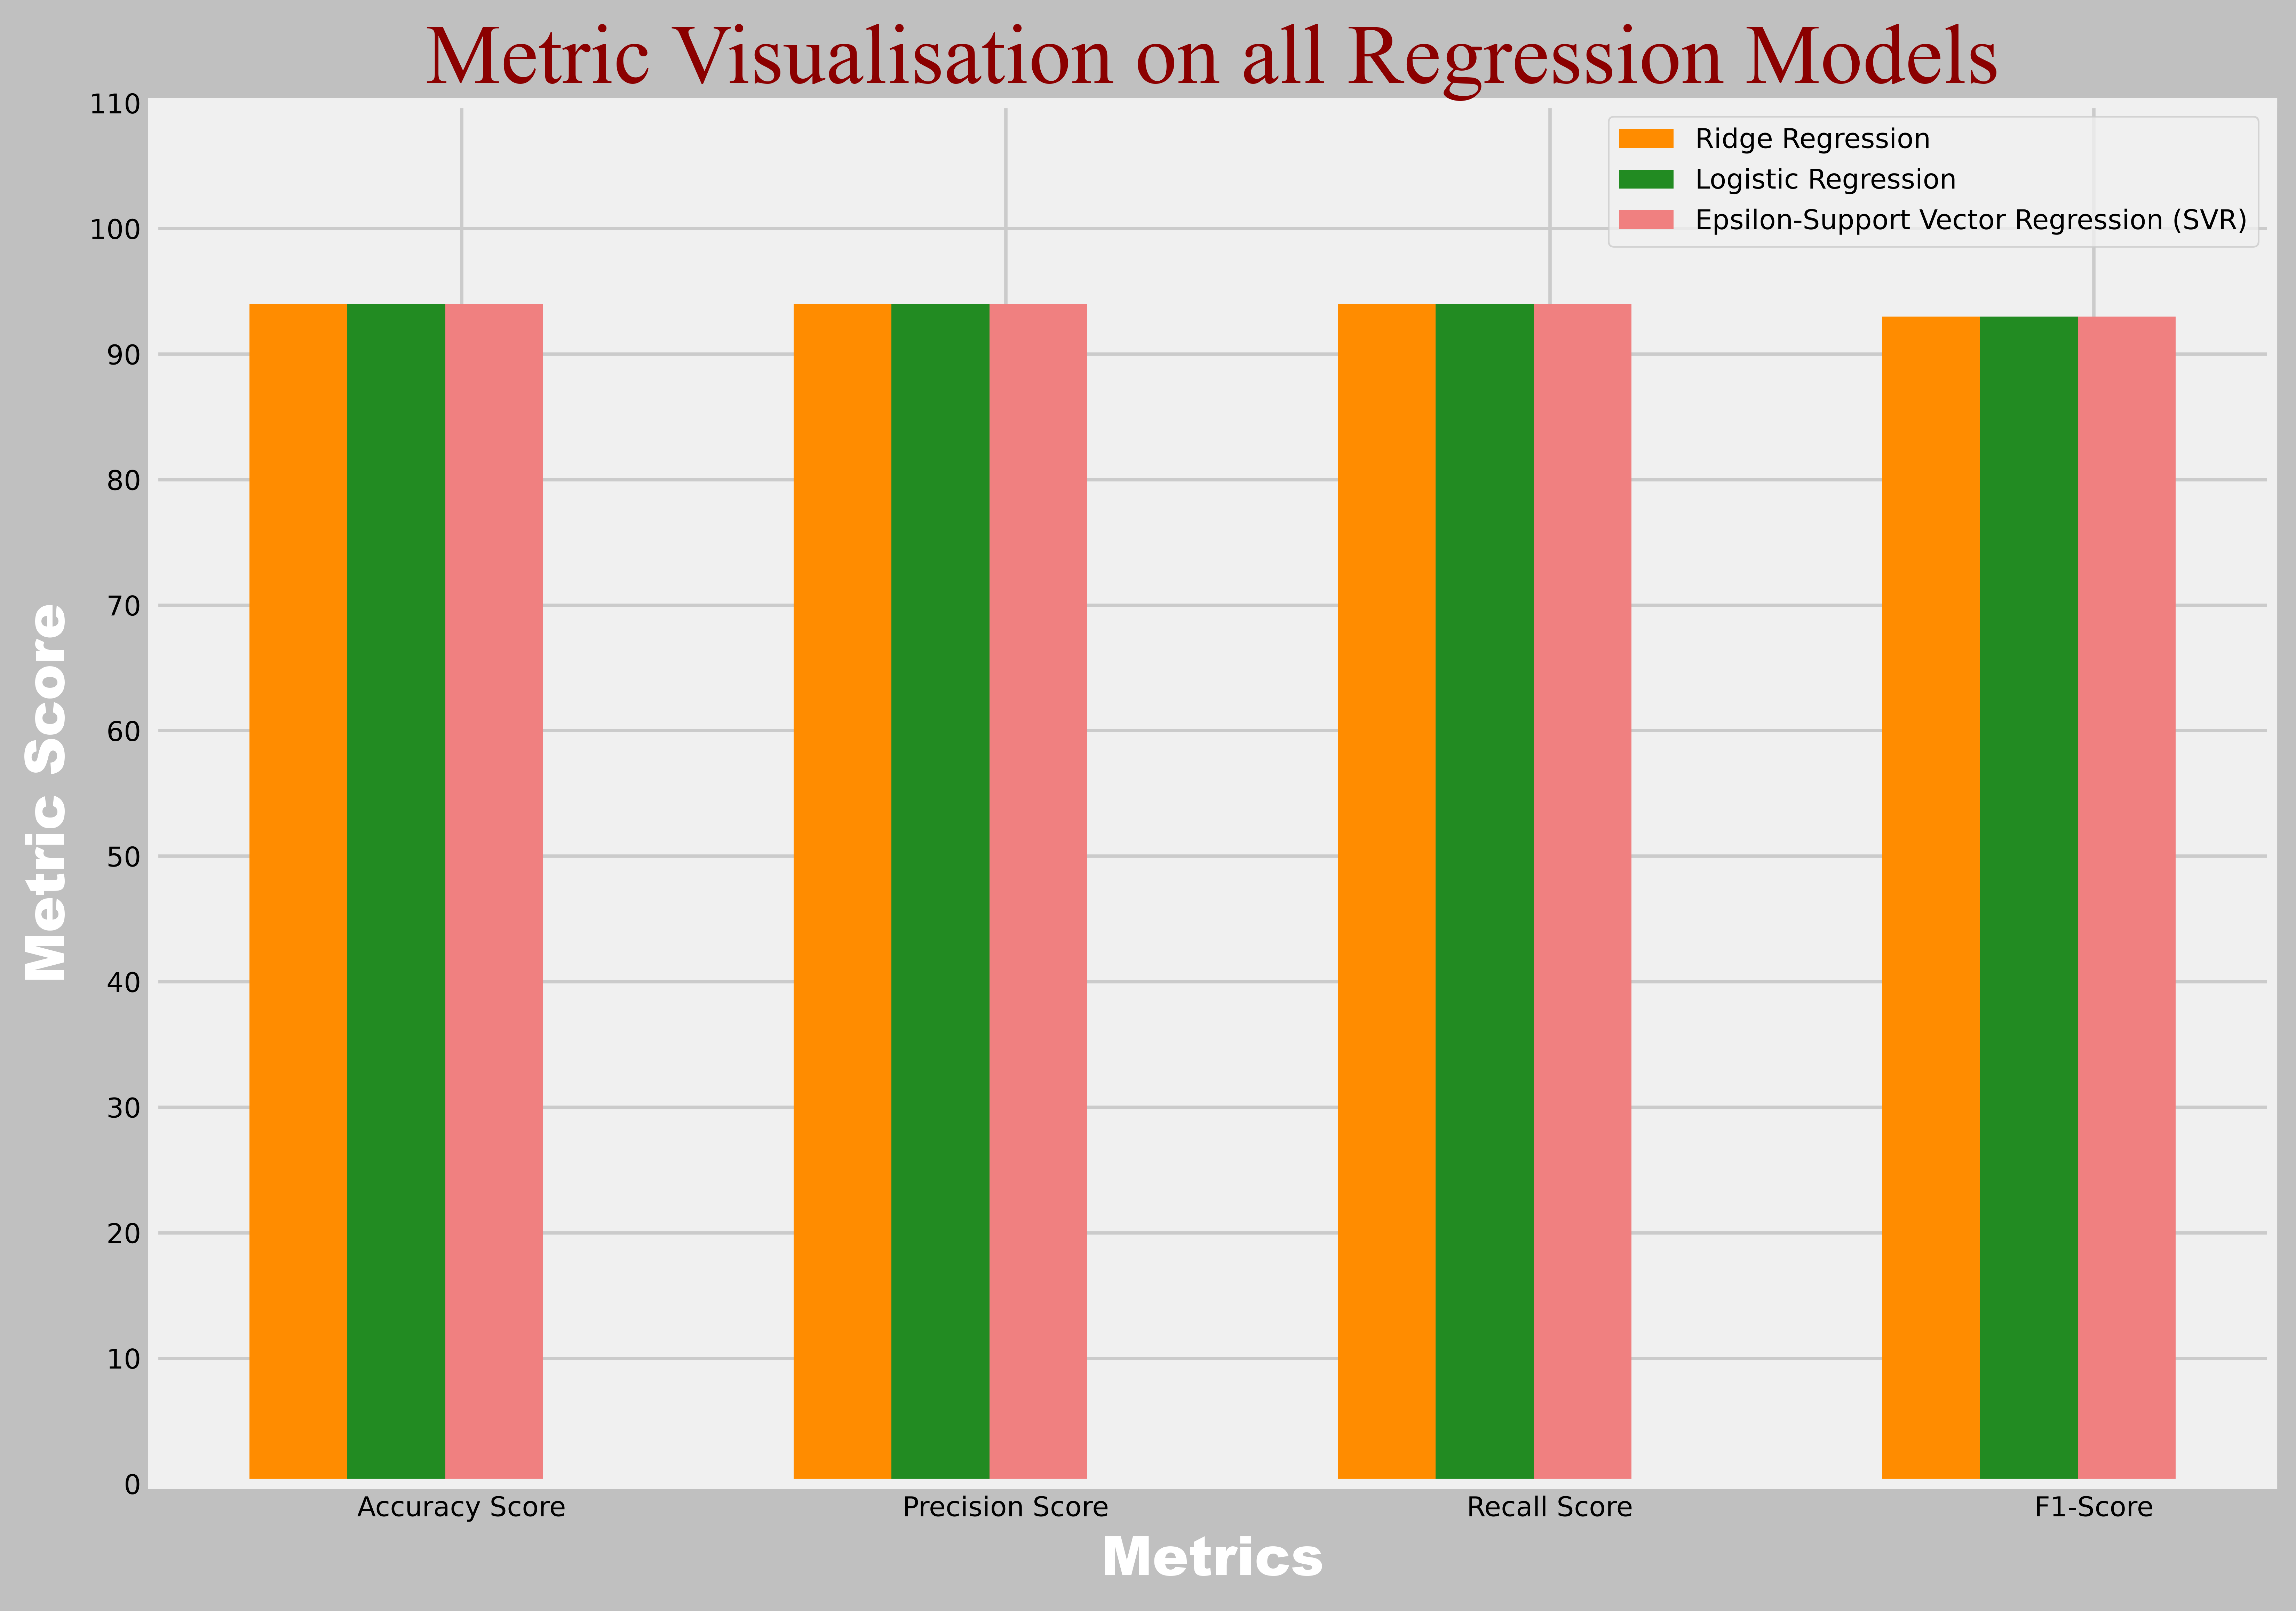

In [52]:
ridge_reg_scores = (
    model_accuracy_scores[0], model_precision_scores[0], model_recall_scores[0], model_f1_scores[0], 
)
lr_scores = (
    model_accuracy_scores[1], model_precision_scores[1], model_recall_scores[1], model_f1_scores[1], 
)
svr_scores = (
    model_accuracy_scores[2], model_precision_scores[2], model_recall_scores[2], model_f1_scores[2], 
)
#sgd_reg_scores = (model_accuracy_scores[3], model_precision_scores[3], model_recall_scores[3], model_f1_scores[3],)
x_grid = ["Accuracy Score", "Precision Score", "Recall Score", "F1-Score"]
y_grid = [value for value in range(0, 120, 10)]
xpos = np.arange(len(x_grid))
bar_width = .18

style.use("fivethirtyeight")
plt.rcParams["font.size"] = 8
plt.figure(figsize=(10, 7), dpi=700, facecolor="silver")
plt.title(  # Add a title to the graph (specify font parameters with the Argument: fontdict).
    "Metric Visualisation on all Regression Models", 
    fontdict={
        "fontname": "Times New Roman", 
        "fontsize": 25
    }, 
    color="darkred"
)
plt.bar(xpos, ridge_reg_scores, width=bar_width, color="darkorange", label="Ridge Regression")
plt.bar((xpos + 0.18), lr_scores, width=bar_width, color="forestgreen", label="Logistic Regression")
plt.bar(
    (xpos + 0.36), svr_scores, width=bar_width, color="lightcoral", 
    label="Epsilon-Support Vector Regression (SVR)"
)
#plt.bar(
    #(xpos + 0.54), sgd_reg_scores, width=bar_width, color="indigo", 
    #label="Stochastic Gradient Descent Regressor - SGD")
plt.xlabel(  # Just like the "Function: plt.title()", this gives a title to the X-Axis.
    "Metrics", 
    fontdict={
        "fontname": "Arial Black", 
        "fontsize": 16
    }, 
    color="white"
)
plt.xticks((xpos + 0.3), x_grid)
plt.ylabel(  # Just like the "Function: plt.title()", this gives a title to the Y-Axis.
    "Metric Score", 
    fontdict={
        "fontname": "Arial Black", 
        "fontsize": 16
    }, 
    color="white"
)
plt.yticks(y_grid)
plt.legend()
plt.show()

**Insight:** Because scores are truncated with `int()`, all three models plot as the same 94 / 94 / 94 / 93 bars, so the chart looks like a three-way tie even though F1 on the bullying class ranges from 33% to 38%. The weighted metrics also reflect mainly the majority class. A chart of **bullying-class** precision, recall and F1 would be more informative.

## Application of GridSearchCV on all Classifier Models

In [53]:
# ------------------------------------- GridSearchCV: Ridge Classifier ------------------------------------- #
ridge_model = RidgeClassifier()
ridge_param_grid = [
    {
        "fit_intercept": [False],
        "max_iter": np.linspace(start = 100, stop = 1000, num = 11, dtype = int),
        "tol": np.logspace(start=-3, stop=-2, num=11),
        "solver": ["auto", "svd", "cholesky", "lsqr", "sparse_cg", "sag", "saga", "lbfgs"],
        "positive": [True]
    }
]
ridge_clf = GridSearchCV(estimator=ridge_model, param_grid=ridge_param_grid, cv=3, n_jobs=-1)
ridge_best_clf = ridge_clf.fit(df_features_train, df_labels_train)
ridge_best_model = ridge_best_clf.best_estimator_

**Insight:** Grid search for `RidgeClassifier` (a true classifier, unlike the Ridge regression above), with the same solver restrictions caused by `positive=True`. Default accuracy scoring favours the majority class.

In [54]:
# ------------------------------ GridSearchCV: Multinomial Naive Bayes (MNB) ------------------------------- #
mnb_model = MultinomialNB()
mnb_param_grid = [
    {
        "alpha": np.logspace(start=0, stop=2, num=30),
        "force_alpha": [True, False],
        "fit_prior": [True, False],
    }
]

mnb_clf = GridSearchCV(estimator=mnb_model, param_grid=mnb_param_grid, cv=3, n_jobs=-1)
mnb_best_clf = mnb_clf.fit(df_features_train, df_labels_train)
mnb_best_model = mnb_best_clf.best_estimator_

**Insight:** Naive Bayes grid. `alpha` is searched only from 1 to 100, so the smaller values that worked better in the baseline (α=0.2 in cell 29) are never tried. Accuracy-based scoring then pushes the search towards heavy smoothing and a majority-class model.

In [55]:
# -------------------------- GridSearchCV: C-Support Vector Classification (SVC) --------------------------- #
svc_model = SVC()
svc_param_grid = [
    {
        "C": np.logspace(start=-2, stop=3, num=7), 
        "kernel": ["linear", "poly", "rbf", "sigmoid"], 
        # "shrinking": [True, False], 
        # "probability": [True, False], 
        # "tol": np.logspace(start=-3, stop=-2, num=11), 
        "max_iter": np.linspace(start=1000, stop=3000, num=11, dtype=int), 
        "decision_function_shape": ["ovo", "ovr"]
        # "break_ties": [True, False]
    }
]

svc_clf = GridSearchCV(estimator=svc_model, param_grid=svc_param_grid, cv=3, n_jobs=-1)
svc_clf_best = svc_clf.fit(df_features_train, df_labels_train)
svc_best_model = svc_clf_best.best_estimator_

**Insight:** SVC grid: 7 C values × 4 kernels × 11 `max_iter` × 2 `decision_function_shape`. Note that `decision_function_shape` (`ovo`/`ovr`) has no effect for a binary problem, so those options just double the computation. Scoring is plain accuracy.

In [ ]:
# ----------------------- GridSearchCV: Stochastic Gradient Descent Classifier (SGD) ----------------------- 
#sgd_model = SGDClassifier()
#sgd_param_grid = [
    #{
        #"loss": ["hinge", "log_loss", "log", "modified_huber", "squared_hinge", "perceptron", 
                 #"squared_error", "huber", "epsilon_insensitive", "squared_epsilon_insensitive"], 
        #"penalty": ["l2", "l1", "elasticnet"], 
        # "alpha": np.linspace(start=0.0001, stop=0.1, num=11, dtype=float), 
        #"fit_intercept": [True, False], 
        #"max_iter": np.linspace(start=1000, stop=3000, num=5, dtype=int), 
        #"shuffle": [True, False], 
        #"learning_rate": ["constant", "optimal", "invscaling", "adaptive"], 
        #"early_stopping": [True, False], 
        # "warm_start": [True, False], 
        #"average": [True, False]
    #}
#]

#sgd_clf = GridSearchCV(estimator=sgd_model, param_grid=sgd_param_grid, cv=3, n_jobs=-1)
#sgd_best_clf = sgd_clf.fit(df_features_train, df_labels_train)
#sgd_best_model = sgd_best_clf.best_estimator_

**Note:** I didn't run the **Stochastic Gradient Descent Classifier** (the grid search above) because it takes too much time to run. It is therefore not included in the classifier comparison.

## Implementing Classifier Models

In [56]:
# The below output displays the best parameters to train with the Regression Models, and is copied on to the 
classifier_best_models = [  # Regression models below...
    ridge_best_model, mnb_best_model, svc_best_model, #sgd_best_model
]

for i, model in enumerate(classifier_best_models):
    print(f"|Model {(i + 1)}|: {model}")

|Model 1|: RidgeClassifier(fit_intercept=False, max_iter=np.int64(100), positive=True,
                tol=np.float64(0.001))
|Model 2|: MultinomialNB(alpha=np.float64(1.0))
|Model 3|: SVC(C=np.float64(3.1622776601683795), decision_function_shape='ovo',
    kernel='sigmoid', max_iter=np.int64(1000))


**Insight — best parameters:**
- **RidgeClassifier:** `max_iter=100`, `tol=0.001`.
- **Multinomial NB:** `alpha=1.0`, the *lower bound* of the grid, which confirms that smaller values were never explored.
- **SVC:** `C≈3.16`, **sigmoid** kernel, `max_iter=1000` (the minimum in the grid, so convergence may be capped).

In [57]:
# ----------------------------------------- Display Metric Result ------------------------------------------ #
models = {
    "Ridge Classifier": Ridge(fit_intercept=False, max_iter=100, positive=True, tol=0.001), 
    "Multinomial Naive Bayes": MultinomialNB(force_alpha=True), 
    "C-Support Vector Classification": SVC(C=3.1622776601683795, decision_function_shape="ovo", max_iter=1000), 
    #"Stochastic Gradient Descent Classifier": SGDClassifier(max_iter=3000, penalty="elasticnet")
}
model_accuracy_scores = []
model_precision_scores = []
model_recall_scores = []
model_f1_scores = []

for model_name, model in models.items():
    # print(model)

    model.fit(df_features_train, df_labels_train)

    model_prediction = model.predict(df_features_test)
    model_accuracy_score = accuracy_score(df_labels_test, model_prediction.round())
    model_precision_score = precision_score(df_labels_test, model_prediction.round(), average="weighted")
    model_recall_score = recall_score(df_labels_test, model_prediction.round(), average="weighted")
    model_f1_score = f1_score(df_labels_test, model_prediction.round(), average="weighted")

    model_accuracy_scores.append(int(model_accuracy_score * 100))
    model_precision_scores.append(int(model_precision_score * 100))
    model_recall_scores.append(int(model_recall_score * 100))
    model_f1_scores.append(int(model_f1_score * 100))
    
    print("Evaluation for: {model_name}".format(model_name=model_name).center(90, '_') + "\n" + 
          "Model Type:      {model_type}".format(model_type=model) + "\n" + 
          "Model Preiction: {model_prediction}".format(model_prediction=model_prediction.round()) + "\n\n" + 

          "Accuracy Score:  {model_accuracy:%}".format(model_accuracy=model_accuracy_score) + "\n" + 
          "Precision Score: {model_precision:%}".format(model_precision=model_precision_score) + "\n" + 
          "Recall Score:    {model_recall:%}".format(model_recall=model_recall_score) + "\n" + 
          "F1-Score:        {model_f1:%}".format(model_f1=model_f1_score) + "\n\n" + 
          
          "{model_name} - Confusion Matrix:".format(model_name=model_name) + "\n" + 
          "{m_confusion_matrix}".format(m_confusion_matrix=confusion_matrix(
              df_labels_test, model_prediction.round())
          ) + "\n\n" + 
          
          "{model_name} - Classification Report:".format(model_name=model_name) + "\n" + 
          "{m_class_report}".format(m_class_report=classification_report(
              df_labels_test, model_prediction.round())
          ) + "\n" + 
          "THE END".center(90, '-'))
# ---------------------------------------------------------------------------------------------------------- #

_____________________________Evaluation for: Ridge Classifier_____________________________
Model Type:      Ridge(fit_intercept=False, max_iter=100, positive=True, tol=0.001)
Model Preiction: [0. 0. 0. ... 0. 0. 0.]

Accuracy Score:  94.903651%
Precision Score: 94.630557%
Recall Score:    94.903651%
F1-Score:        93.367112%

Ridge Classifier - Confusion Matrix:
[[3693    6]
 [ 195   50]]

Ridge Classifier - Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      3699
           1       0.89      0.20      0.33       245

    accuracy                           0.95      3944
   macro avg       0.92      0.60      0.65      3944
weighted avg       0.95      0.95      0.93      3944

-----------------------------------------THE END------------------------------------------
_________________________Evaluation for: Multinomial Naive Bayes__________________________
Model Type:      MultinomialNB()
Model Preiction: [0 0

**Insight — classifiers on pre-processed features (positive class = bullying):**

| Model | Accuracy | Precision | Recall | F1 | Confusion matrix |
|---|---|---|---|---|---|
| "Ridge Classifier" | 94.90% | 89.3% | 20.4% | 33.2% | [[3693, 6], [195, 50]] |
| Multinomial NB (α=1) | 93.81% | 100% (1 prediction) | 0.4% | 0.8% | [[3699, 0], [244, 1]] |
| SVC (C≈3.16, RBF as run) | 94.98% | 73.7% | 29.8% | 42.4% | [[3673, 26], [172, 73]] |

- **SVC is the best model in the notebook** on bullying-class F1 (0.42) and recall (≈30%), while keeping precision near 74%. It also has the highest accuracy (94.98%).
- **Naive Bayes at α=1 collapses to "always No"**: it flags a single post, so its 93.81% accuracy is no better than the 93.79% majority baseline. Compare the baseline NB with α=0.2 (recall 16.7%).
- *Notes:* (1) the "Ridge Classifier" entry is actually `Ridge` (regression), so its numbers are identical to cell 57, and the tuned `RidgeClassifier` is never evaluated; (2) the SVC was rebuilt without `kernel="sigmoid"`, so it ran with the default RBF kernel rather than the tuned configuration.

## Visualising the Metric Scores for all Classifier Models

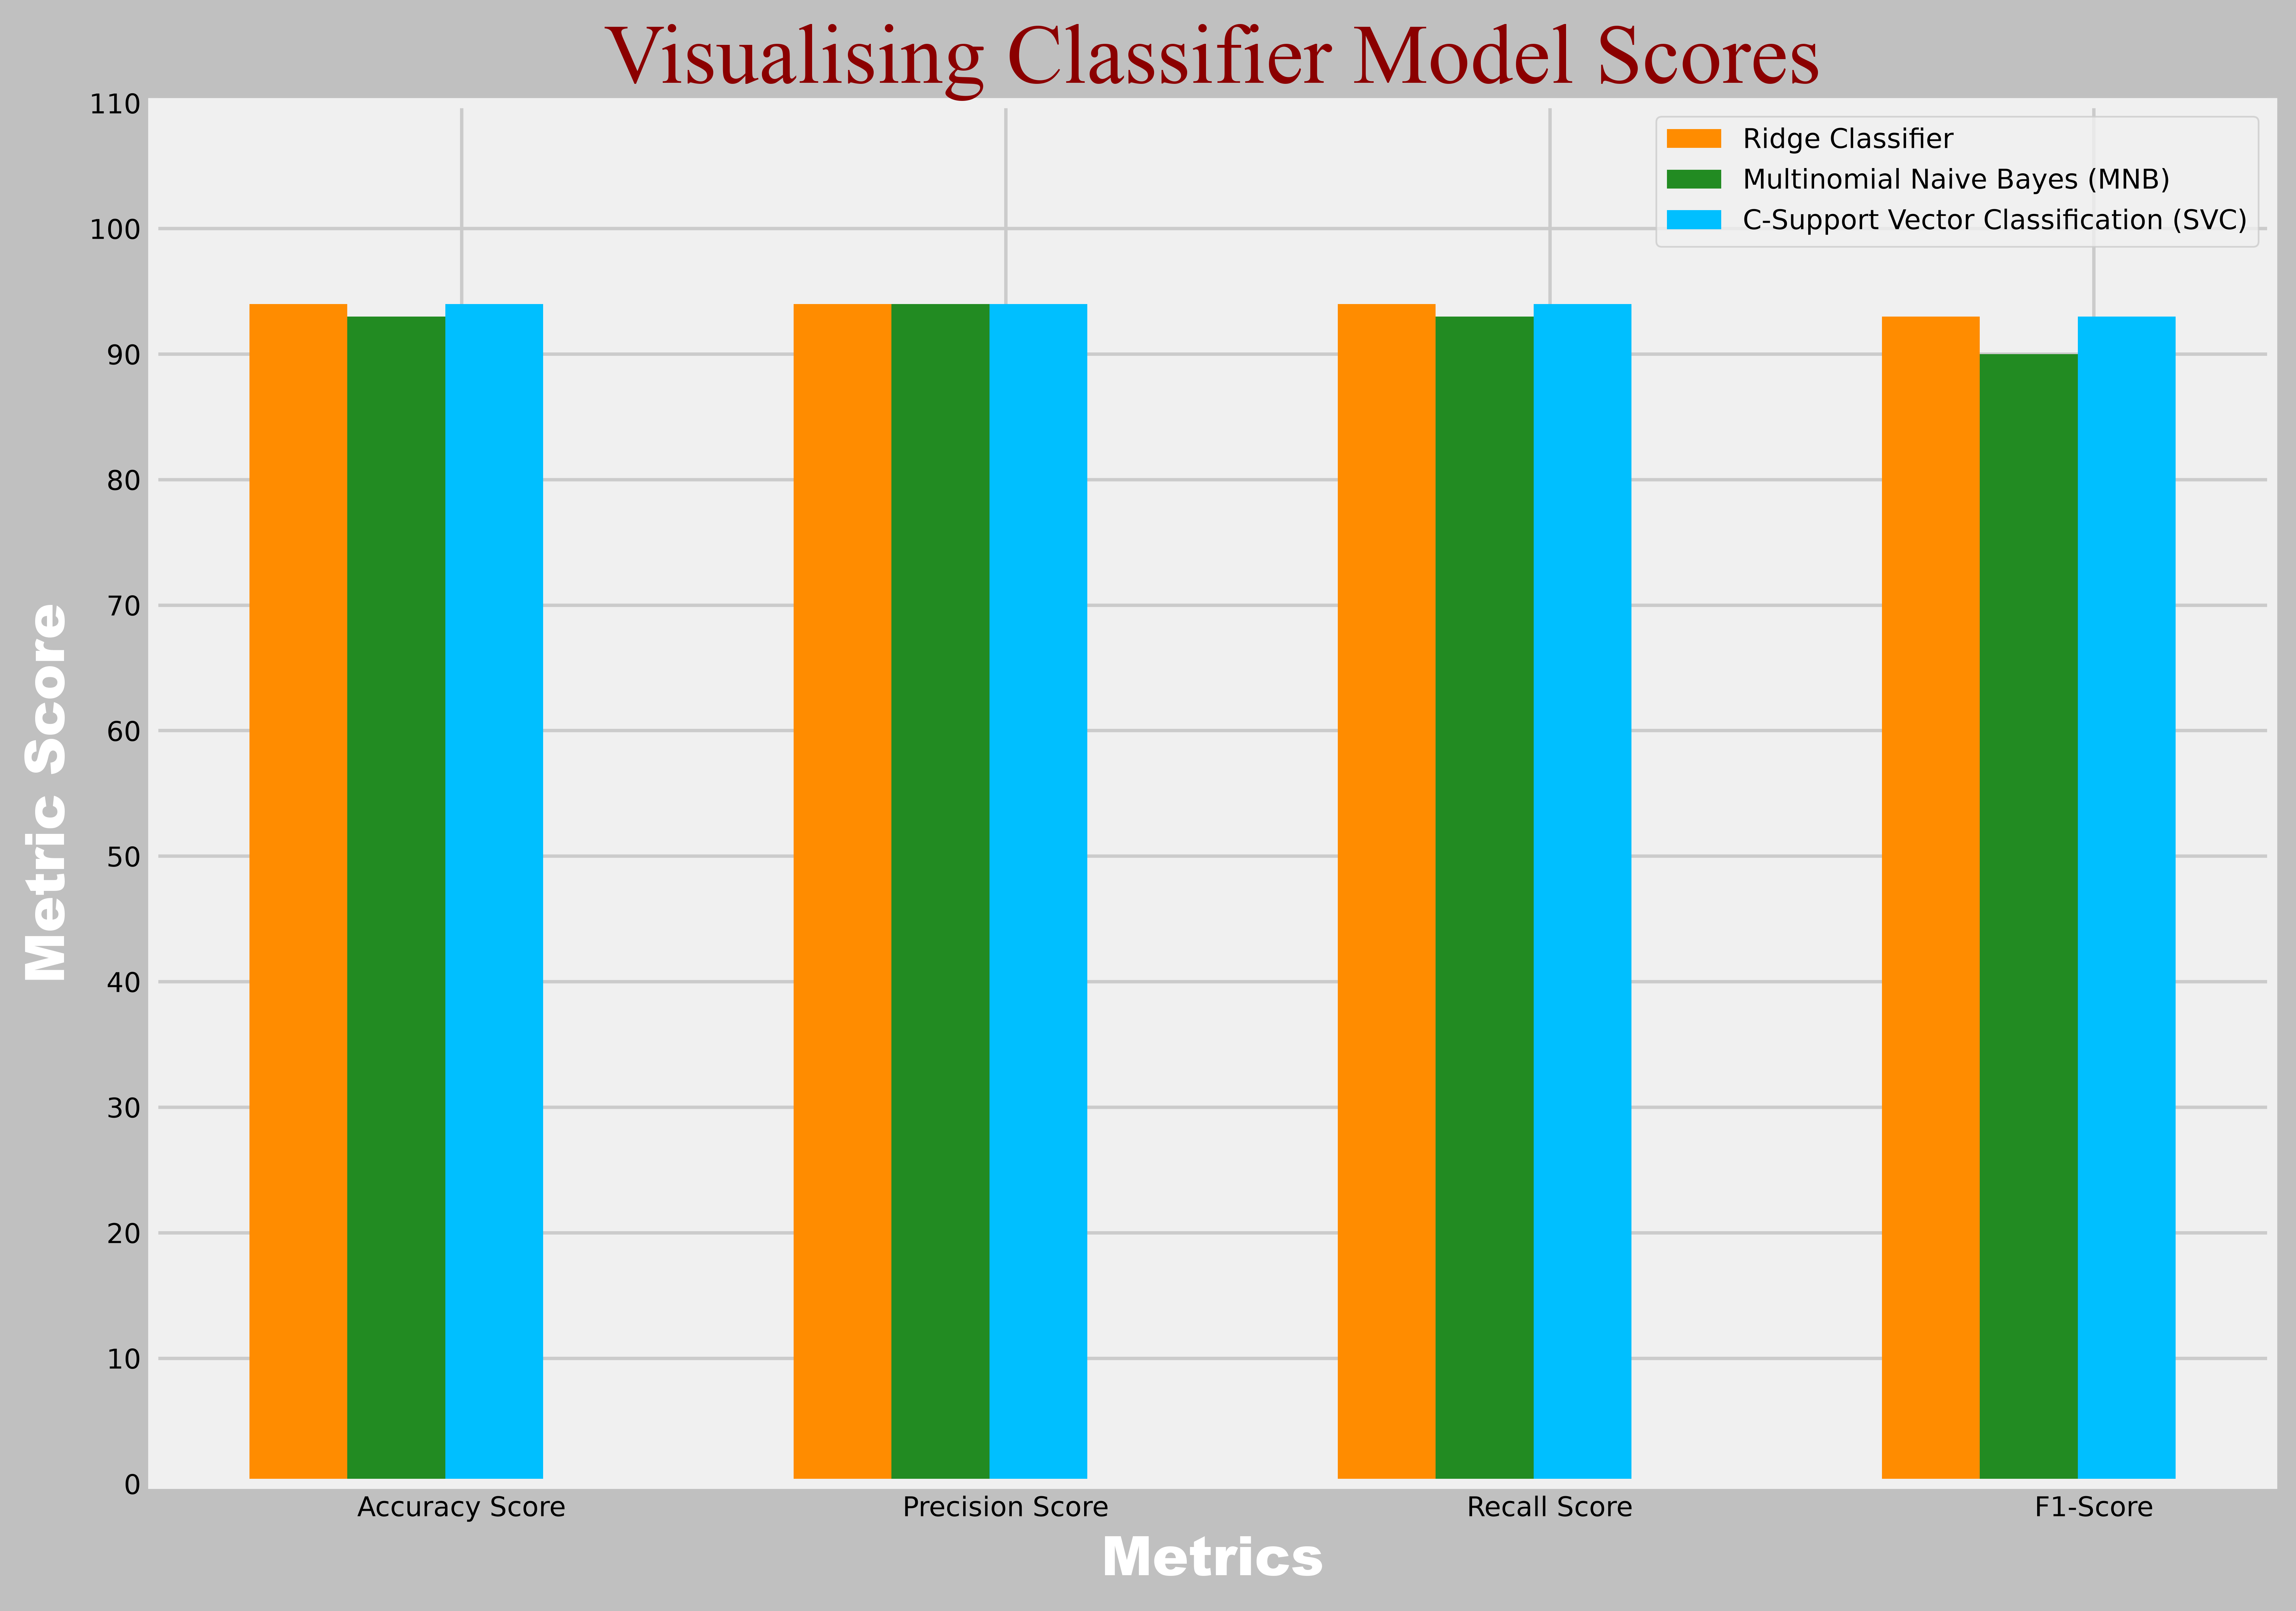

In [58]:
ridge_scores = [
    model_accuracy_scores[0], model_precision_scores[0], model_recall_scores[0], model_f1_scores[0], 
]
mnb_scores = [
    model_accuracy_scores[1], model_precision_scores[1], model_recall_scores[1], model_f1_scores[1], 
]
svc_scores = [
    model_accuracy_scores[2], model_precision_scores[2], model_recall_scores[2], model_f1_scores[2], 
]
#sgd_scores = [model_accuracy_scores[3], model_precision_scores[3], model_recall_scores[3], model_f1_scores[3], ]
x_grid = ["Accuracy Score", "Precision Score", "Recall Score", "F1-Score"]
y_grid = [value for value in range(0, 120, 10)]
xpos = np.arange(len(x_grid))
bar_width = .18

style.use("fivethirtyeight")
plt.rcParams["font.size"] = 8
plt.figure(figsize=(10, 7), dpi=700, facecolor="silver")
plt.title(  # Add a title to the graph (specify font parameters with the Argument: fontdict).
    "Visualising Classifier Model Scores", 
    fontdict={
        "fontname": "Times New Roman", 
        "fontsize": 25
    }, 
    color="darkred"
)
plt.bar(xpos, ridge_scores, width=bar_width, color="darkorange", label="Ridge Classifier")
plt.bar(
    (xpos + 0.18), mnb_scores, width=bar_width, color="forestgreen", label="Multinomial Naive Bayes (MNB)"
)
plt.bar(
    (xpos + 0.36), svc_scores, width=bar_width, color="deepskyblue", 
    label="C-Support Vector Classification (SVC)"
)
#plt.bar((xpos + 0.54), sgd_scores, width=bar_width, color="lightcoral", label="Stochastic Gradient Descent Classifier (SGD)")
plt.xlabel(  # Just like the "Function: plt.title()", this gives a title to the X-Axis.
    "Metrics", 
    fontdict={
        "fontname": "Arial Black", 
        "fontsize": 16
    }, 
    color="white"
)
plt.xticks((xpos + 0.3), x_grid)
plt.ylabel(  # Just like the "Function: plt.title()", this gives a title to the Y-Axis.
    "Metric Score", 
    fontdict={
        "fontname": "Arial Black", 
        "fontsize": 16
    }, 
    color="white"
)
plt.yticks(y_grid)
plt.legend()
plt.show()

**Insight:** Truncated scores again make Ridge and SVC appear identical (94 / 94 / 94 / 93) and show only NB lower (F1 90), hiding SVC's real edge on the bullying class (recall 30% vs 20%, F1 0.42 vs 0.33). Plotting the minority-class metrics (or macro-F1) would make the model ranking visible.

## Conclusion

**Goal:** classify Formspring Q&A posts as cyberbullying (`Yes`) or not (`No`) using TF-IDF text features and classical ML models.

### Key findings
1. **Data:** 13,144 unique posts (3 duplicates removed), no missing values. The target is **highly imbalanced** — 93.5% non-bullying vs 6.5% bullying (≈14 : 1). The "always No" baseline already gets ≈93.8% accuracy on the test set.
2. **Pre-processing:** stop-word removal and stemming cut non-zero TF-IDF entries by ≈42%, but stripping punctuation before decoding HTML left artefact tokens (`bra`, `039`, glued words), so the vocabulary actually grew (18,775 → 20,771).
3. **Model comparison (bullying class, same 70/30 split):**

| Model | Features | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|
| SVC (C≈3.16, RBF as run) | cleaned | 94.98% | 73.7% | 29.8% | **42.4%** |
| Decision Tree | raw | 93.26% | 44.7% | **36.3%** | 40.1% |
| SVC (sigmoid, γ=1) | raw | 95.06% | 82.9% | 25.7% | 39.3% |
| Logistic Regression (l1) | cleaned | 94.95% | 81.1% | 24.5% | 37.6% |
| SVR (sigmoid, rounded) | cleaned | 94.95% | 88.3% | 21.6% | 34.8% |
| Ridge (rounded) | cleaned | 94.90% | **89.3%** | 20.4% | 33.2% |
| Multinomial NB (α=0.2) | raw | 94.04% | 56.9% | 16.7% | 25.9% |
| Multinomial NB (α=1) | cleaned | 93.81% | 100% (1 flag) | 0.4% | 0.8% |

4. **Best overall:** the tuned-feature **SVC** gives the best balance (F1 0.42, ≈74% precision, ≈30% recall). The **Decision Tree** has the highest recall (36%) at much lower precision. The **Ridge/SVR/Logistic** group is the most precise but also the most conservative.
5. **Accuracy is not the story:** every reasonable model lands at 94–95%, only ≈1 point above the majority baseline. The meaningful differences are in bullying-class recall and F1, which the truncated, weighted-metric bar charts do not show.

### What this means in practice
The models are **high-precision, low-recall**: when they flag a post as bullying they are usually right, but they miss roughly 70–80% of genuine bullying posts. For a moderation use case, where missing harmful content is costly, this is not yet deployment-ready.

### Limitations and fixes spotted in the notebook
- Split is not stratified, and TF-IDF is fitted on the full corpus before splitting (mild leakage); use a `Pipeline` with stratified CV.
- Tuning used accuracy / R² / weighted-F1 scoring, which favours the majority class; use `f1` or `average_precision` on the bullying class.
- Some final models were rebuilt with parameters different from the tuned ones (Logistic `C`/`tol`, SVC kernel; "Ridge Classifier" is actually `Ridge`), and the NB `alpha` grid excluded values below 1.
- Several best parameters sit on grid boundaries (LR `C`/`tol`, NB `alpha`, `max_iter`), so the search ranges should be widened.
- The Stochastic Gradient Descent Classifier and Regressor were not run because they take too much time, so they are not part of the comparison.
- Cleaning order should be: unescape HTML → remove `<br>` and `Q:`/`A:` markers → lowercase → tokenise → stop-words → stem.

### Recommended next steps
1. Use `class_weight="balanced"` (or resample the **training** folds only) and evaluate with a stratified 5-fold CV on PR-AUC / bullying-class F1.
2. Tune the decision threshold from the precision-recall curve to trade some precision for recall.
3. Add character n-gram TF-IDF to handle slang and misspellings, and try `LinearSVC` / `ComplementNB`.
4. Test the unused `Length` feature, and later a fine-tuned transformer (e.g. DistilBERT) for context-aware detection.
5. Report macro-F1 and bullying-class metrics instead of accuracy and weighted averages.